# Austin Housing Price Prediction

**Data:** Austin, TX home listings scraped from Zillow (`austinHousingData.csv`, ~15,000 listings sold 2018-2021).
**Goal:** Explore the data and build a regression model that predicts `latestPrice` (the most recent sale price).

**Outline**
1. Load and inspect the data
2. Cleaning
3. Exploratory data analysis (EDA)
4. Feature engineering
5. Modelling: baseline, Ridge, Random Forest, Gradient Boosting
6. Evaluation and error analysis
7. Feature importance
8. Conclusions and limitations

> Place `austinHousingData.csv` in the same folder as this notebook (or change `DATA_PATH`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = "austinHousingData.csv"

## 1. Load and inspect

In [2]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(3).T

(15171, 47)


,0,1,2
zpid,111373431,120900430,2084491383
city,pflugerville,pflugerville,pflugerville
streetAddress,14424 Lake Victor Dr,1104 Strickling Dr,1408 Fort Dessau Rd
zipcode,78660,78660,78660
description,"14424 Lake Victor Dr, Pflugerville, TX 78660 i...",Absolutely GORGEOUS 4 Bedroom home with 2 full...,Under construction - estimated completion in A...
latitude,30.430632,30.432673,30.409748
longitude,-97.663078,-97.661697,-97.639771
propertyTaxRate,1.98,1.98,1.98
garageSpaces,2,2,0
hasAssociation,True,True,True


In [3]:
print(raw.dtypes.value_counts())
print("\nMissing values:\n", raw.isna().sum()[lambda s: s > 0])
print("\nDuplicate zpid:", raw.zpid.duplicated().sum())
raw[["latestPrice","livingAreaSqFt","lotSizeSqFt","numOfBathrooms","numOfBedrooms","yearBuilt"]].describe().T

int64      25
float64     9
str         7
bool        6
Name: count, dtype: int64

Missing values:
 description    2
dtype: int64

Duplicate zpid: 0


,count,mean,std,min,25%,50%,75%,max
latestPrice,15171.0,512767.743722,4.531853e+05,5500.0,309000.0,405000.0,575000.0,1.350000e+07
livingAreaSqFt,15171.0,2208.323314,1.378576e+03,300.0,1483.0,1975.0,2687.0,1.092920e+05
lotSizeSqFt,15171.0,119083.968123,1.225272e+07,100.0,6534.0,8276.0,10890.0,1.508483e+09
numOfBathrooms,15171.0,2.683010,1.054445e+00,0.0,2.0,3.0,3.0,2.700000e+01
numOfBedrooms,15171.0,3.440380,8.499418e-01,0.0,3.0,3.0,4.0,2.000000e+01
yearBuilt,15171.0,1988.554743,2.157946e+01,1905.0,1974.0,1993.0,2006.0,2.020000e+03


Observations: almost no missing data, `latestPrice` has a very long right tail, and some size columns contain impossible values (e.g. a lot of 1.5 billion sq ft), so cleaning is needed.

## 2. Cleaning

In [4]:
df = raw.copy()
n0 = len(df)

# Drop non-predictive identifiers / free text / URLs
df = df.drop(columns=["zpid", "streetAddress", "description", "homeImage", "city", "latestPriceSource"])

# Keep property types that are actual homes; drop land and rare categories
print(df.homeType.value_counts())
df = df[~df.homeType.isin(["Vacant Land", "Other"])]
df["homeType"] = df.homeType.where(df.homeType.map(df.homeType.value_counts()) >= 30, "Other")

# Remove impossible / extreme values
df = df[df.livingAreaSqFt.between(400, 10_000)]
df = df[df.lotSizeSqFt.between(500, 500_000)]       # 500,000 sq ft = ~11.5 acres
df = df[df.latestPrice.between(50_000, 5_000_000)]  # drop nominal-price / extreme records
df = df[df.numOfBedrooms.between(0, 10) & df.numOfBathrooms.between(1, 10)]

print(f"\nRows kept: {len(df):,} of {n0:,} ({len(df)/n0:.1%})")

homeType
Single Family            14241
Condo                      470
Townhouse                  174
Multiple Occupancy          96
Vacant Land                 83
Residential                 37
Apartment                   37
Mobile / Manufactured       17
MultiFamily                 10
Other                        6
Name: count, dtype: int64

Rows kept: 14,966 of 15,171 (98.6%)


## 3. Exploratory data analysis

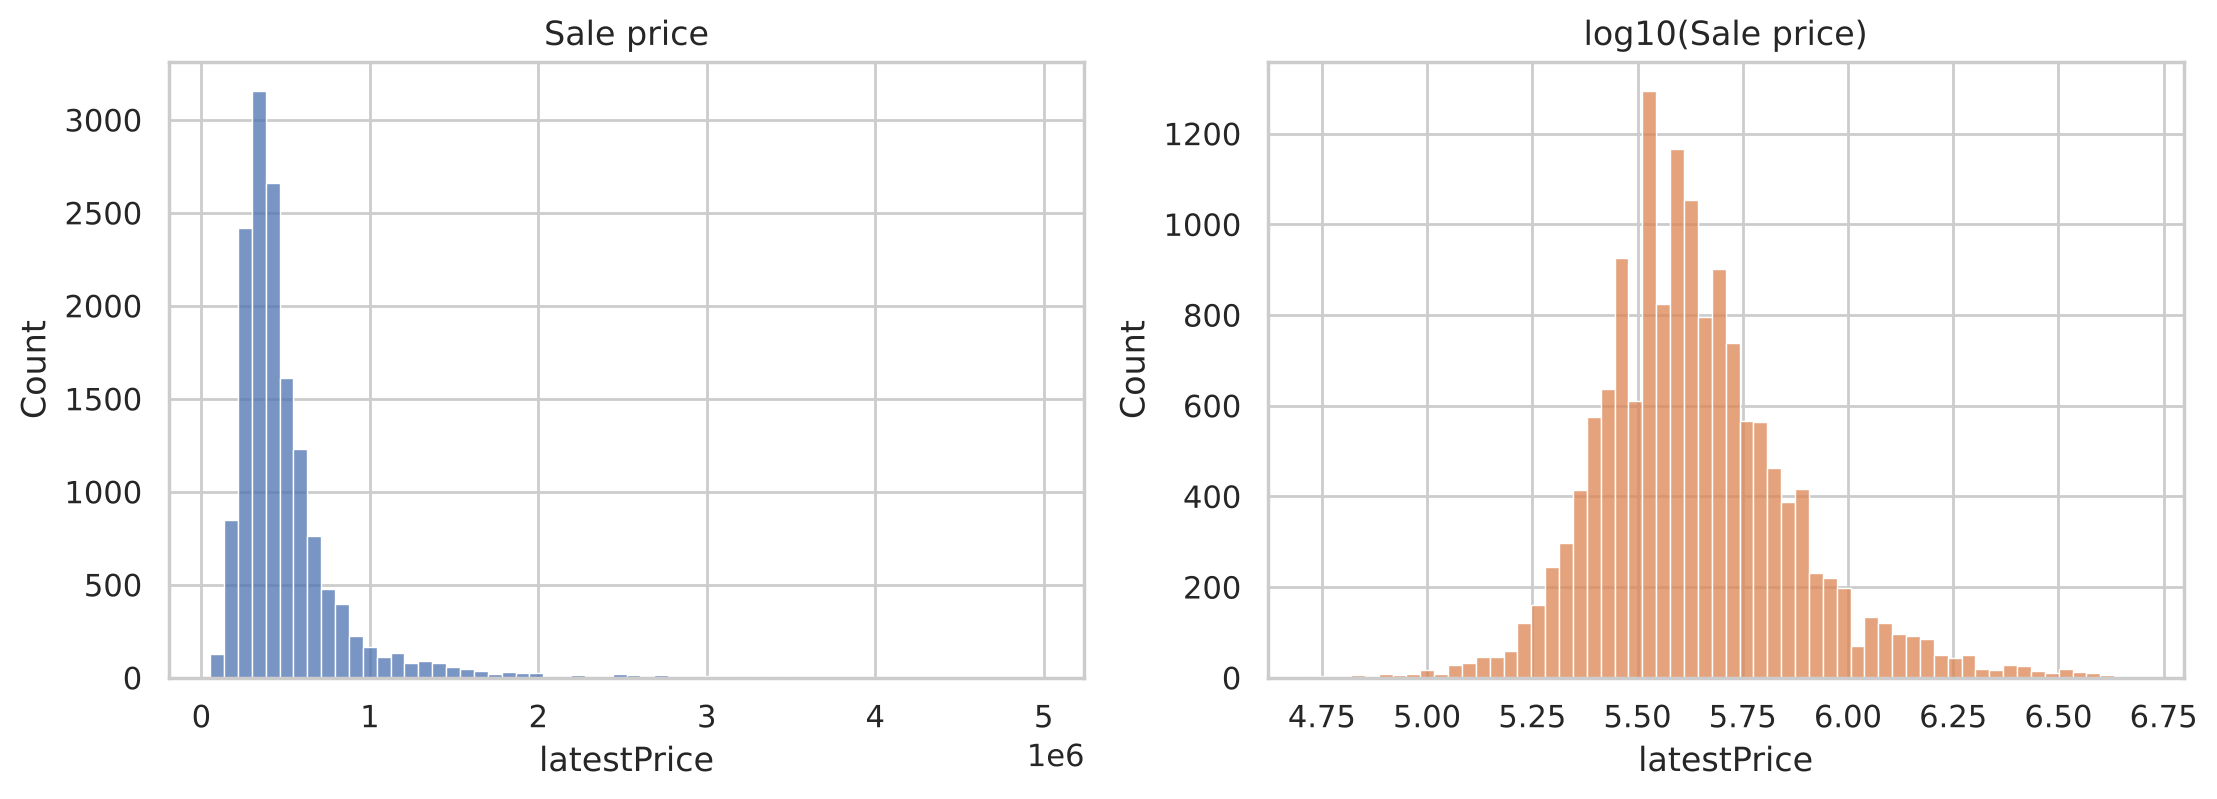

Skew raw: 3.99 | skew log: 0.68


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.latestPrice, bins=60, ax=ax[0]); ax[0].set_title("Sale price")
sns.histplot(np.log10(df.latestPrice), bins=60, ax=ax[1], color="C1"); ax[1].set_title("log10(Sale price)")
plt.show()
print("Skew raw: %.2f | skew log: %.2f" % (df.latestPrice.skew(), np.log(df.latestPrice).skew()))

Prices are right-skewed; the log transform is far more symmetric. We will **model log(price)** so errors are proportional (a $50k miss matters differently on a $250k and a $2M house).

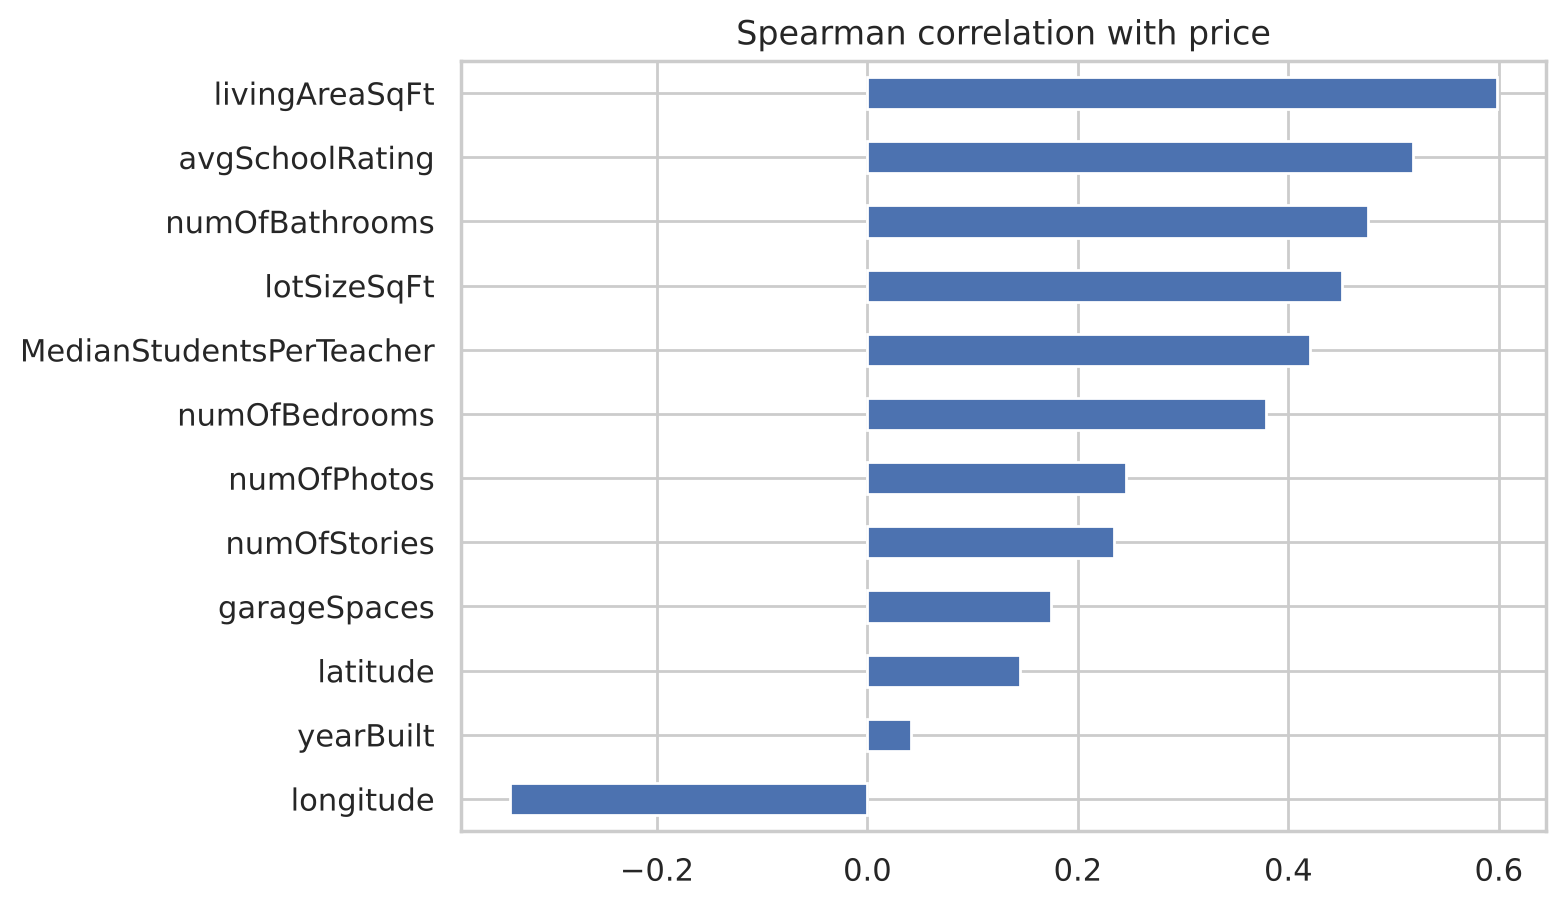

In [6]:
num_cols = ["livingAreaSqFt","numOfBathrooms","numOfBedrooms","lotSizeSqFt","yearBuilt","garageSpaces",
            "numOfStories","avgSchoolRating","numOfPhotos","latitude","longitude","MedianStudentsPerTeacher"]
corr = df[num_cols + ["latestPrice"]].corr(method="spearman")["latestPrice"].drop("latestPrice").sort_values()
corr.plot.barh(figsize=(7, 5), title="Spearman correlation with price")
plt.show()

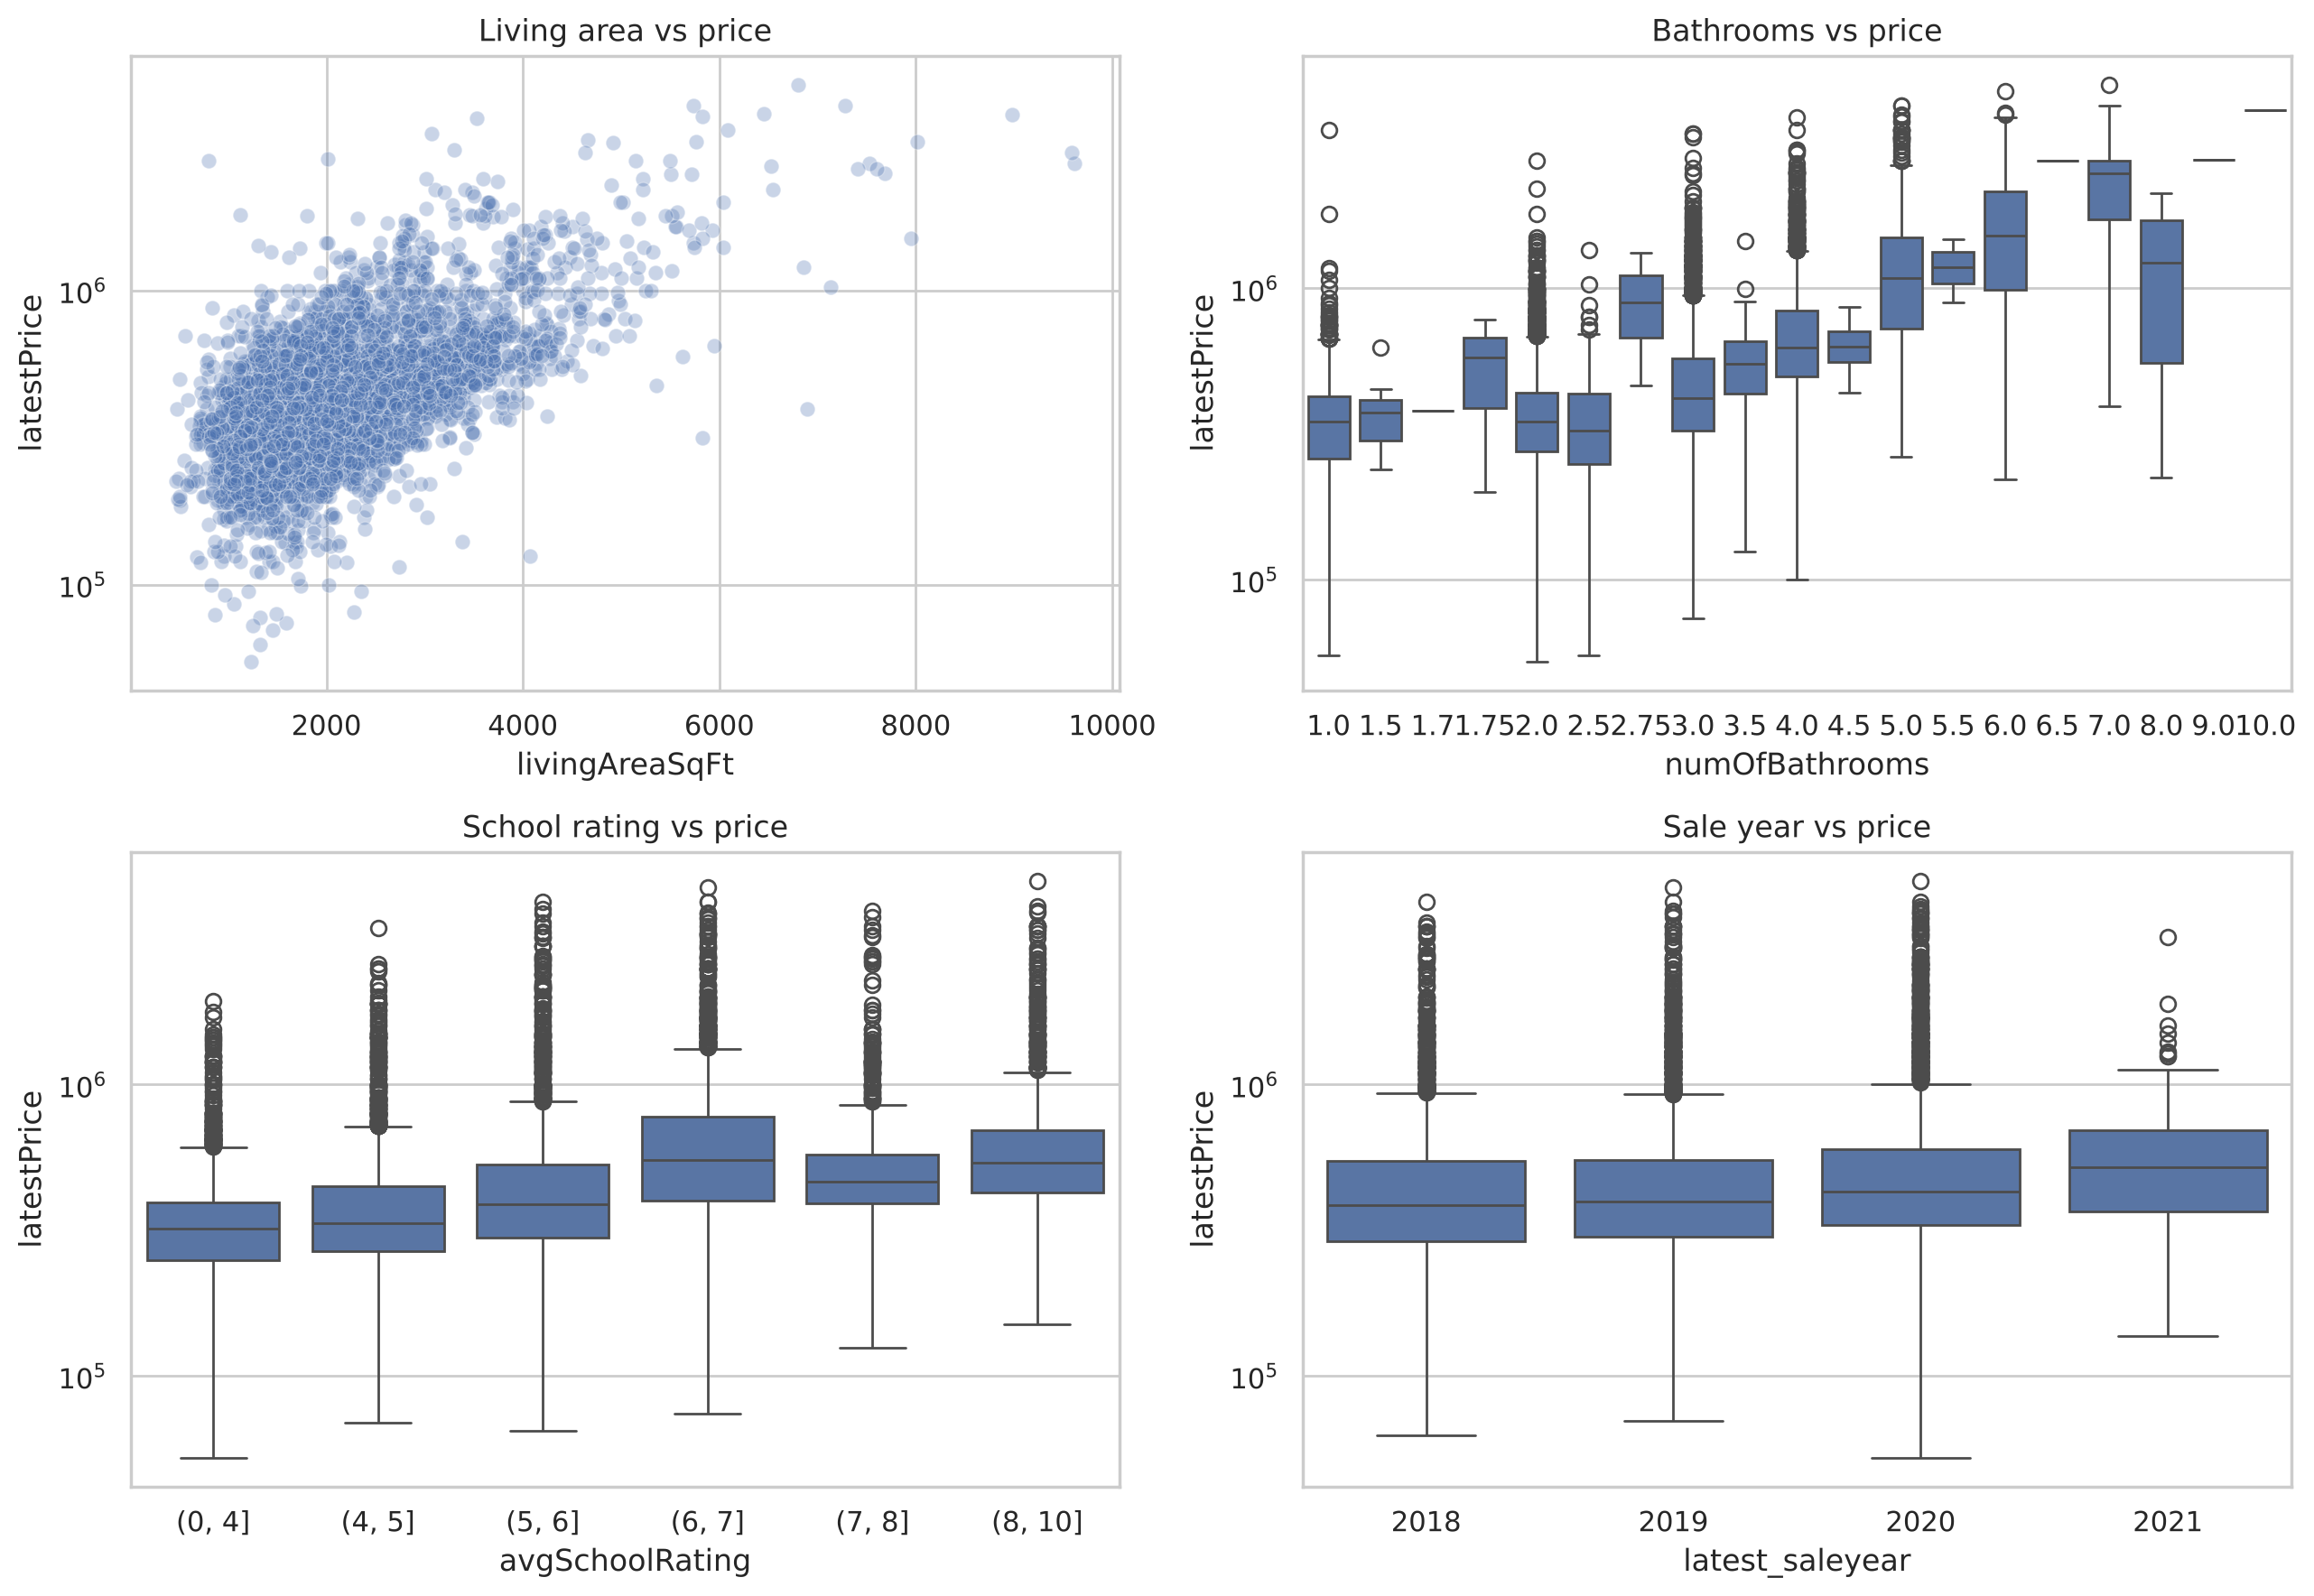

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(data=df.sample(4000, random_state=0), x="livingAreaSqFt", y="latestPrice", alpha=.3, ax=ax[0,0])
ax[0,0].set_title("Living area vs price")
sns.boxplot(data=df, x="numOfBathrooms", y="latestPrice", ax=ax[0,1]); ax[0,1].set_title("Bathrooms vs price")
sns.boxplot(data=df, x=pd.cut(df.avgSchoolRating, [0,4,5,6,7,8,10]), y="latestPrice", ax=ax[1,0])
ax[1,0].set_title("School rating vs price"); ax[1,0].set_xlabel("avgSchoolRating")
sns.boxplot(data=df, x="latest_saleyear", y="latestPrice", ax=ax[1,1]); ax[1,1].set_title("Sale year vs price")
for a in ax.ravel(): a.set_yscale("log")
plt.tight_layout(); plt.show()

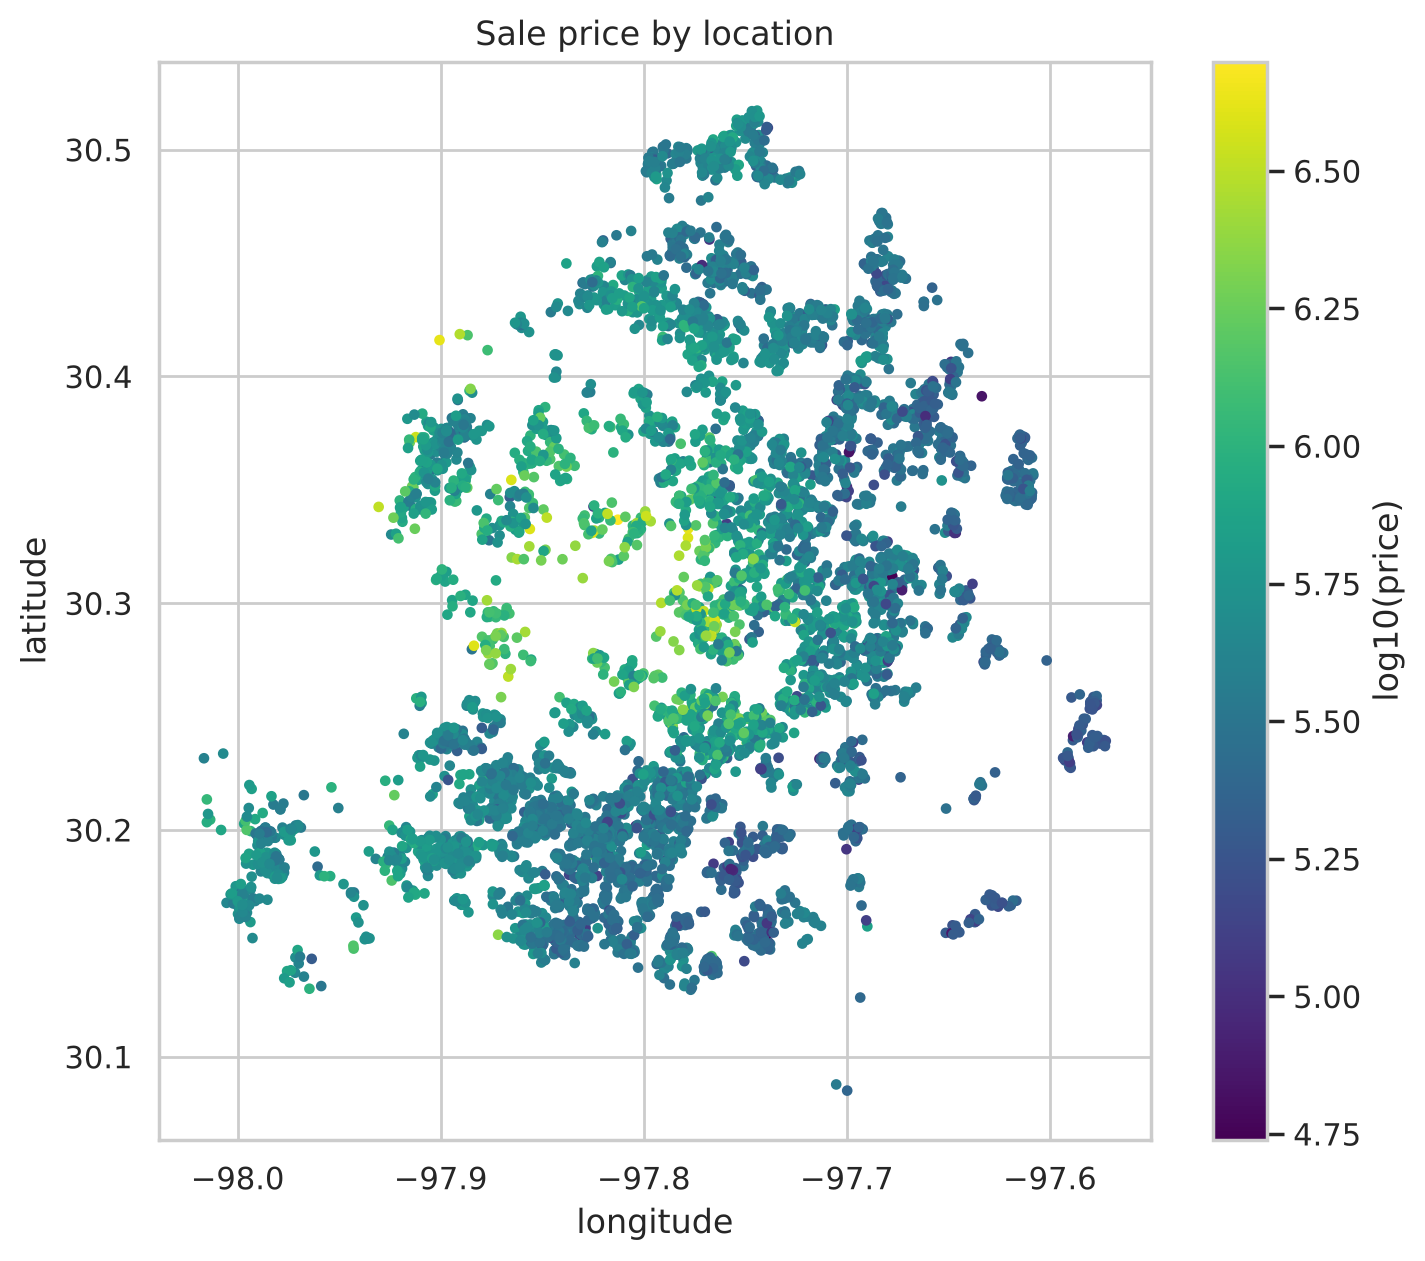

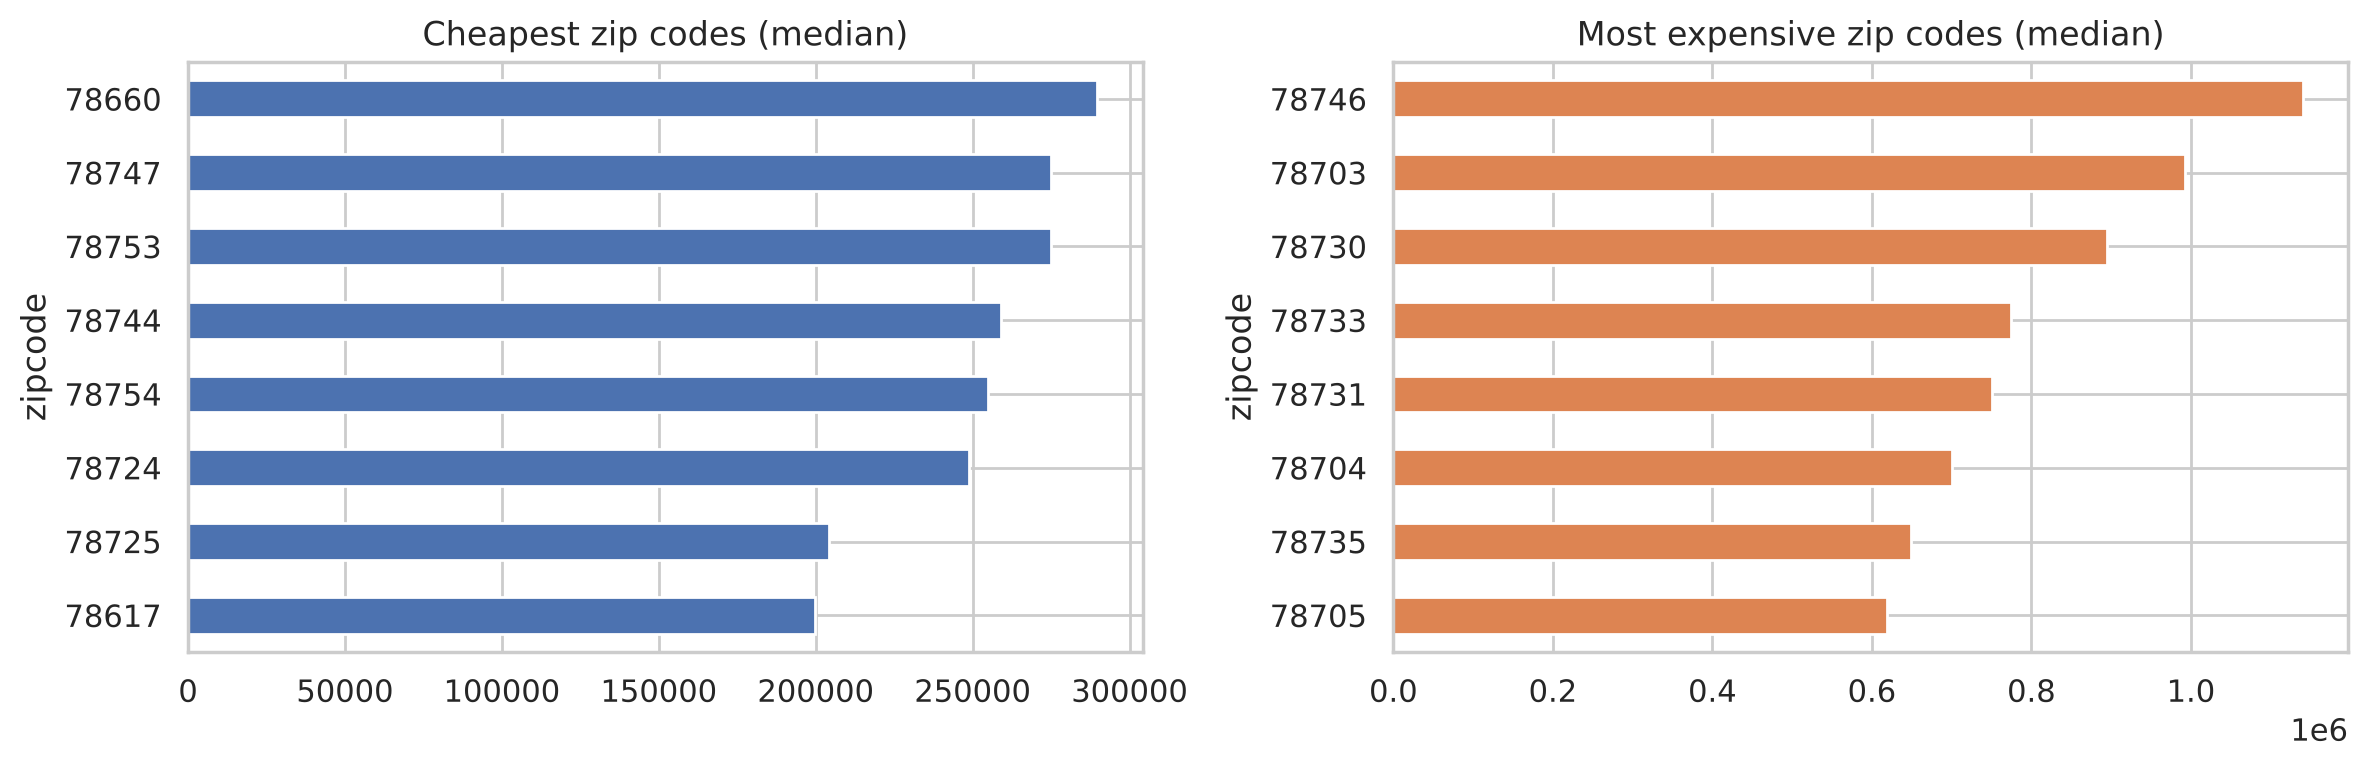

In [8]:
# Geography: where are the expensive homes?
s = df.sample(6000, random_state=0)
plt.figure(figsize=(8, 7))
sc = plt.scatter(s.longitude, s.latitude, c=np.log10(s.latestPrice), s=8, cmap="viridis")
plt.colorbar(sc, label="log10(price)"); plt.title("Sale price by location")
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.show()

zip_stats = df.groupby("zipcode").latestPrice.agg(["count","median"]).query("count>=30").sort_values("median")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
zip_stats["median"].head(8).plot.barh(ax=ax[0], title="Cheapest zip codes (median)")
zip_stats["median"].tail(8).plot.barh(ax=ax[1], title="Most expensive zip codes (median)", color="C1")
plt.tight_layout(); plt.show()

Location matters a lot: see the map and zip-code charts for which areas are priciest. Living area, bathrooms and school rating are the strongest home-level correlates.

## 4. Feature engineering

* `dist_downtown_km`: haversine distance to downtown Austin (30.2672, -97.7431)
* `age`: sale year minus year built
* `sale_period`: months since Jan 2018, to capture the 2018-2021 market appreciation
* Ratios: `bath_per_bed`, `lot_to_living`
* Log of lot size (very skewed)
* `zipcode` treated as a **categorical** variable

In [9]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlmb/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

def engineer(d):
    d = d.copy()
    d["dist_downtown_km"] = haversine(d.latitude, d.longitude, 30.2672, -97.7431)
    d["age"] = (d.latest_saleyear - d.yearBuilt).clip(lower=0)
    d["sale_period"] = (d.latest_saleyear - 2018) * 12 + d.latest_salemonth
    d["bath_per_bed"] = d.numOfBathrooms / d.numOfBedrooms.clip(lower=1)
    d["log_lot"] = np.log1p(d.lotSizeSqFt)
    d["lot_to_living"] = d.lotSizeSqFt / d.livingAreaSqFt
    d["zipcode"] = d.zipcode.astype(str)
    for c in d.select_dtypes("bool"): d[c] = d[c].astype(int)
    return d.drop(columns=["latest_saledate", "latestPrice"], errors="ignore")

X = engineer(df)
y = df.latestPrice
cat_cols = ["zipcode", "homeType"]
num_cols = [c for c in X.columns if c not in cat_cols]
print(len(num_cols), "numeric +", len(cat_cols), "categorical features")

43 numeric + 2 categorical features


## 5. Modelling

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

def make_pipe(model, scale=False, ohe=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    cat = OneHotEncoder(handle_unknown="ignore", min_frequency=10)
    pre = ColumnTransformer([("num", Pipeline(num), num_cols), ("cat", cat, cat_cols)])
    # Fit on log(price), report in dollars
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("model", model)]),
                                      func=np.log, inverse_func=np.exp)

models = {
    "Baseline (median)": make_pipe(DummyRegressor(strategy="median")),
    "Ridge": make_pipe(RidgeCV(alphas=np.logspace(-2, 3, 20)), scale=True),
    "Random Forest": make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
    "Hist Gradient Boosting": make_pipe(HistGradientBoostingRegressor(learning_rate=0.06, max_iter=500, max_leaf_nodes=24,
                                         l2_regularization=1.0, early_stopping=True, random_state=RANDOM_STATE)),
}

cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    r2 = cross_val_score(m, X_train, y_train, cv=cv, scoring="r2", n_jobs=1)
    rows.append({"model": name, "CV R2 mean": r2.mean(), "CV R2 std": r2.std()})
cv_table = pd.DataFrame(rows).set_index("model").round(4)
cv_table

(11972, 45) (2994, 45)


,CV R2 mean,CV R2 std
model,,
Baseline (median),-0.0747,0.0062
Ridge,0.7402,0.0181
Random Forest,0.7647,0.0111
Hist Gradient Boosting,0.7707,0.0139


### Hyperparameter tuning (gradient boosting)

In [11]:
from sklearn.model_selection import RandomizedSearchCV
base = make_pipe(HistGradientBoostingRegressor(early_stopping=True, random_state=RANDOM_STATE))
param_dist = {
    "regressor__model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "regressor__model__max_iter": [300, 600, 1000],
    "regressor__model__max_leaf_nodes": [15, 24, 31, 45],
    "regressor__model__min_samples_leaf": [10, 20, 40],
    "regressor__model__l2_regularization": [0, 1, 5, 10],
}
search = RandomizedSearchCV(base, param_dist, n_iter=15, cv=3, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", {k.split("__")[-1]: v for k, v in search.best_params_.items()})
best = search.best_estimator_

Best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 45, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 5}


## 6. Evaluation on the held-out test set

In [12]:
def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE ($)": mean_absolute_error(y_true, y_pred),
            "Median AE ($)": median_absolute_error(y_true, y_pred),
            "MAPE (%)": np.mean(np.abs(y_true - y_pred) / y_true) * 100,
            "Within 10%": np.mean(np.abs(y_true - y_pred) / y_true <= 0.10) * 100}

final = {}
for name, m in models.items():
    final[name] = metrics(y_test, m.fit(X_train, y_train).predict(X_test))
final["Tuned HistGB"] = metrics(y_test, best.predict(X_test))
results = pd.DataFrame(final).T.round(3)
results

,R2,RMSE ($),MAE ($),Median AE ($),MAPE (%),Within 10%
Baseline (median),-0.089,372298.976,204924.051,119000.000,38.618,18.236
Ridge,0.753,177305.999,86653.557,46228.966,17.857,45.691
Random Forest,0.792,162780.305,77027.385,37930.302,15.297,53.373
Hist Gradient Boosting,0.821,151046.672,76217.677,40168.065,15.333,51.436
Tuned HistGB,0.822,150700.536,75238.554,38814.001,15.026,52.338


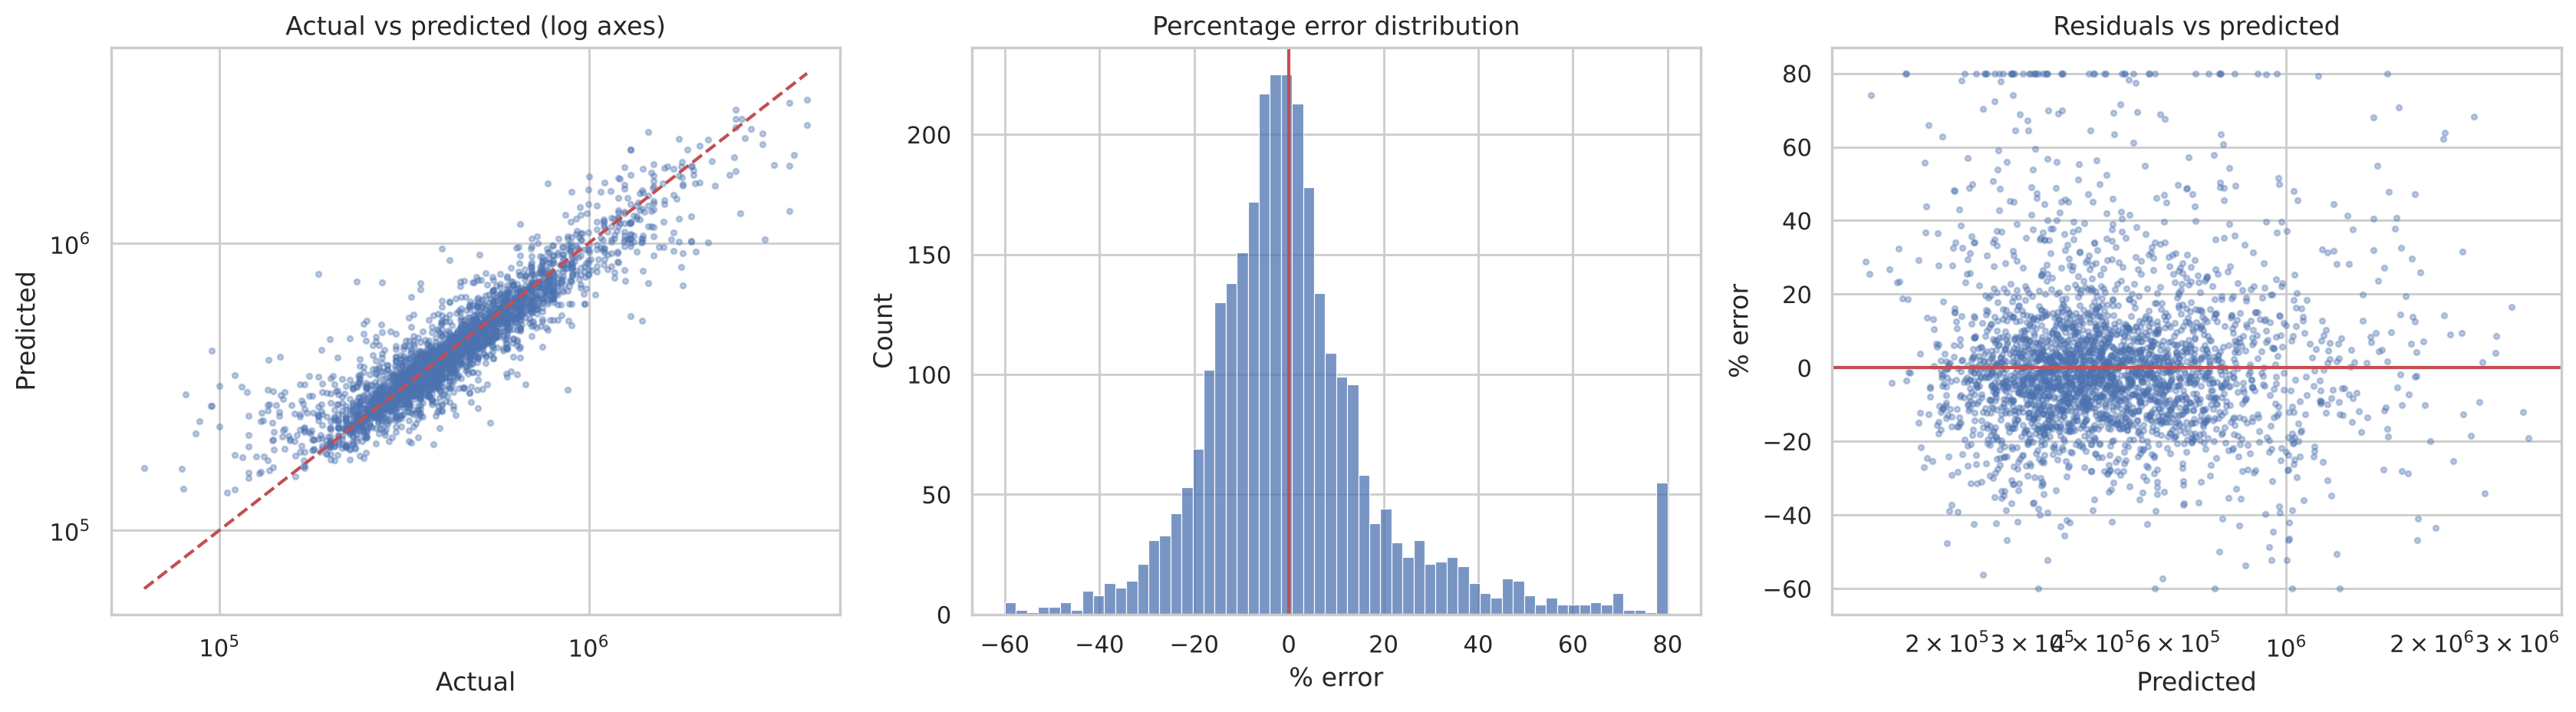

In [13]:
pred = best.predict(X_test)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(y_test, pred, s=6, alpha=.35)
lim = [y_test.min(), y_test.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set(title="Actual vs predicted (log axes)", xlabel="Actual", ylabel="Predicted")
resid = (pred - y_test) / y_test * 100
sns.histplot(resid.clip(-60, 80), bins=60, ax=ax[1]); ax[1].axvline(0, color="r")
ax[1].set(title="Percentage error distribution", xlabel="% error")
ax[2].scatter(pred, resid.clip(-60, 80), s=6, alpha=.35); ax[2].axhline(0, color="r")
ax[2].set_xscale("log"); ax[2].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="% error")
plt.tight_layout(); plt.show()

In [14]:
# Where does the model struggle? Error by price band
bands = pd.qcut(y_test, 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
err = pd.DataFrame({"band": bands, "ape": np.abs(pred - y_test) / y_test * 100, "bias": resid})
err.groupby("band").agg(median_abs_pct_error=("ape", "median"), mean_bias_pct=("bias", "mean")).round(1)

,median_abs_pct_error,mean_bias_pct
band,,
Q1 (lowest),11.3,20.8
Q2,7.5,1.6
Q3,7.9,-1.9
Q4,8.7,-2.6
Q5 (highest),12.8,-6.3


## 7. Feature importance

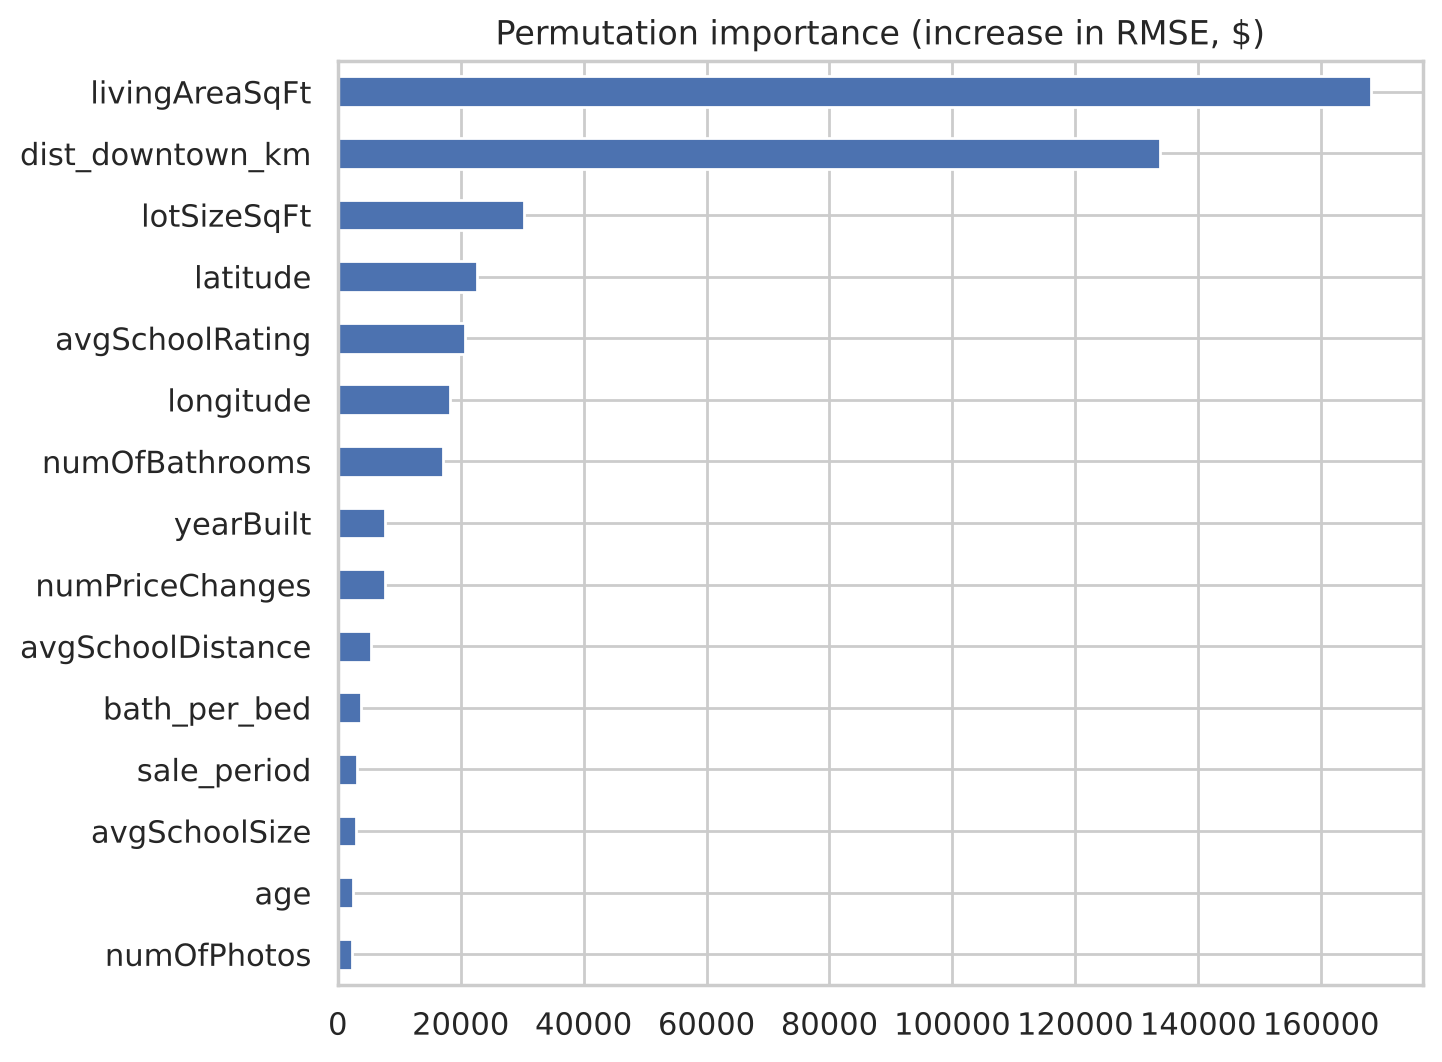

In [15]:
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(15)
imp.plot.barh(figsize=(7, 6), title="Permutation importance (increase in RMSE, $)")
plt.show()

## 8. Predicting a new home

In [16]:
example = X_test.iloc[[0]].copy()
print(example[["livingAreaSqFt","numOfBedrooms","numOfBathrooms","zipcode","yearBuilt","avgSchoolRating"]].to_string(index=False))
print(f"\nPredicted: ${best.predict(example)[0]:,.0f}   |   Actual: ${y_test.iloc[0]:,.0f}")

# To score your own house: copy a row of X, edit the columns, and call best.predict(row)

 livingAreaSqFt  numOfBedrooms  numOfBathrooms zipcode  yearBuilt  avgSchoolRating
         2808.0              4             3.0   78727       1999         4.333333

Predicted: $453,310   |   Actual: $435,000


## 9. Conclusions and limitations

**Key findings** (from the run saved in this notebook)
* The tuned gradient boosting model reaches **R² ≈ 0.82** on the held-out test set, with a **median absolute error of about $39k** and about 52% of predictions within 10% of the actual price. A linear Ridge model reaches R² ≈ 0.75, and the median-price baseline is far behind.
* Living area and distance to downtown are by far the most important features, followed by lot size, latitude/longitude, school rating and bathrooms. Zip code adds little once coordinates and downtown distance are present.
* Modelling log(price) and treating zip code as categorical helped; boosted trees beat Random Forest and Ridge.
* The model **over-predicts the cheapest 20% of homes by about 21% on average** and under-predicts the top 20% by about 6%. Error is also highest at both ends of the price range (median absolute % error is 11-13% in the bottom and top quintiles, versus 8% in the middle).

**Limitations**
* Listings cover 2018-2021 only; the Austin market has moved considerably since, so predictions must be re-based (retrain on recent data) before real-world use.
* `latestPrice` is the last listed/sold price and can include data-entry noise.
* Condition, renovation quality, and interior finishes are not captured; the listing `description` text and photos could add signal (NLP and image models are natural next steps).
* Random split can leak neighbourhood information across train/test; for forecasting, use a time-based split.

**Next steps:** add text features from `description` (TF-IDF), try target-encoding zip codes, stack models, and validate with a time-based split.